# Generating drift

**Drift** is a systematic shift of the data distribution: the same
data-generating process starts producing values that are translated
(or scaled) compared to what you saw before. It is one of the most
common defects in production ML systems — a sensor slowly degrades, a
supplier changes units, an upstream model update shifts an input.

This notebook shows the **two levers** badgers gives you to inject
drift:

1. **Acting on the observation process** — directly translate the
   observed values of one or several columns. No causal model is
   involved; these generators (`RandomShiftGenerator`,
   `RandomShiftClassesGenerator`) *do not use a DGP* and do not
   propagate anything: the change is exactly the shift you ask for.
2. **Acting on the data-generating process (DGP)** — perturb a node of
   a *fitted causal model* and let the shift **propagate** to the
   descendants through the structural equations
   (`CausalDriftGenerator`).

Both accept a **selector** to decide which rows are affected
(see the *Understanding badgers* notebook for the selector contract).


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from numpy.random import default_rng
from sklearn.datasets import make_blobs

from badgers.generators.tabular_data.drift import RandomShiftGenerator, RandomShiftClassesGenerator

rng = default_rng(seed=0)


In [ ]:
X, y = make_blobs(centers=4, random_state=0)
# classes are a column of X (y is deprecated as a data carrier)
Xc = np.column_stack([X, y])
column_mapping = {'f0': 0, 'f1': 1, 'cls': 2}
cls = Xc[:, column_mapping['cls']]   # explicit class vector for plotting
print(X.shape, '->', Xc.shape)

## Part A — Acting on the observation process (no DGP)

**What the generators do:** they standardize `X` (each column to mean
0, variance 1), add a random shift, and un-standardize. The result is
a translation of the observed values only — no causal structure is
used, and nothing propagates beyond the shifted columns.

### Translate all rows (every value of the selected columns)


In [5]:
trf = RandomShiftGenerator(random_generator=rng)
Xt, yt = trf.generate(X=X.copy(), y=y, shift_std=np.array([1.,1.]))

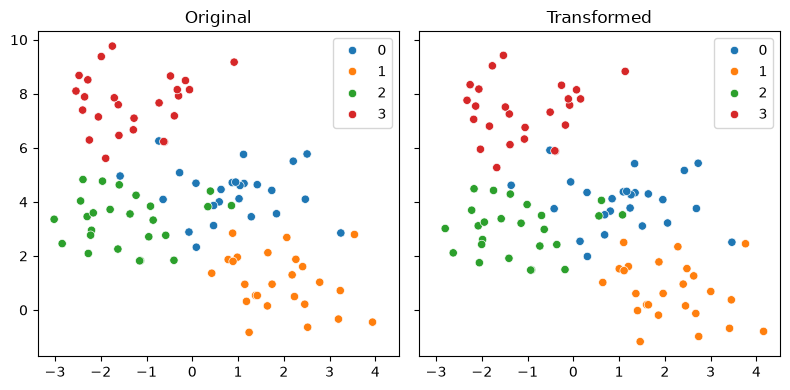

In [6]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette=sns.color_palette("tab10")[:4], legend=True, ax=axes[0])
sns.scatterplot(x=Xt[:, 0], y=Xt[:, 1], hue=yt, palette=sns.color_palette("tab10")[:4], legend=True, ax=axes[1])
axes[0].set_title('Original')
axes[1].set_title('Transformed')
plt.tight_layout()

### Translate per class

The class values are read from a column of `X` (here the last column,
`cls`). A `ClassSelector` builds one boolean mask per class value:
each class gets its own independent shift.


In [ ]:
from badgers.core.selectors import ClassSelector

column_mapping = {"f0": 0, "f1": 1, "cls": 2}
selector = ClassSelector("cls", column_mapping, {"cls": {0: 1., 1: 1., 2: 1., 3: 1.}}, rng=rng)
trf = RandomShiftClassesGenerator(random_generator=rng)
Xt, yt = trf.generate(X=Xc.copy(), y=y, selector=selector, shift_std=2.0)


In [ ]:
# per-class shift magnitude: one value per class (isotropic per class)
trf = RandomShiftClassesGenerator(random_generator=rng)
Xt, yt = trf.generate(X=Xc.copy(), y=y, selector=selector,
                      shift_std={0: 4.0, 1: 2.0, 2: 4.0, 3: 0.0})


In [ ]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
sns.scatterplot(x=Xc[:, 0], y=Xc[:, 1], hue=cls, palette=sns.color_palette("tab10")[:4], legend=True, ax=axes[0])
sns.scatterplot(x=Xt[:, 0], y=Xt[:, 1], hue=Xt[:, 2], palette=sns.color_palette("tab10")[:4], legend=True, ax=axes[1])
axes[0].set_title('Original')
axes[1].set_title('Transformed')
plt.tight_layout()


In [ ]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
sns.scatterplot(x=Xc[:, 0], y=Xc[:, 1], hue=cls, palette=sns.color_palette("tab10")[:4], legend=True, ax=axes[0])
sns.scatterplot(x=Xt[:, 0], y=Xt[:, 1], hue=Xt[:, 2], palette=sns.color_palette("tab10")[:4], legend=True, ax=axes[1])
axes[0].set_title('Original')
axes[1].set_title('Transformed')
plt.tight_layout()


### What `shift_std` / `drift_std` actually mean

Both parameters express the shift **in units of the column's standard
deviation** (`sigma`). Internally every drift generator does:

```
z = (X - mean) / std          # normalize: each column has sigma = 1
z += shift                    # shift drawn from N(0, shift_std * sigma)
X' = z * std + mean           # un-normalize
```

So `shift_std = 2` on column `f0` means exactly: *"move column `f0` by
2 of its own standard deviations"* — a column with a wide range gets a
proportionally larger absolute shift than a narrow one. The drawn
shift is a single value per column, applied to **all** affected rows
(that is what makes it *drift* and not *noise* — noise redraws per
row).


In [ ]:
# verify the semantics: the shift DRAWN for f0, expressed in sigma units,
# equals a draw from N(0, shift_std) -- i.e. shift_std sets the scale of the
# shift in standard deviations, it is not the shift itself.
X_test = X[:, :2].astype(float).copy()
gen = RandomShiftGenerator(random_generator=default_rng(42))
Xt_test, _ = gen.generate(X_test, None, shift_std=np.array([2.0, 0.0]))

sigma0 = X_test[:, 0].std()                 # sigma of the ORIGINAL column
observed_z = (Xt_test[:, 0] - X_test[:, 0]).mean() / sigma0
expected_z = default_rng(42).normal(0., 2.0, size=2)[0]  # the same draw
print(f'shift of f0 in sigma units: {observed_z:.4f}')
print(f'draw from N(0, shift_std=2):  {expected_z:.4f}')
print('match:', np.isclose(observed_z, expected_z))
print('f1 untouched:', np.allclose(Xt_test[:, 1], X_test[:, 1]))

In [ ]:
from badgers.generators.tabular_data.drift.causal import CausalDriftGenerator
from badgers.core.dgp import OlsDGP


## Part B — Acting on the data-generating process (DGP)

**What the generator does:** `CausalDriftGenerator` takes a *fitted
DGP* (a causal model of your data). It shifts a node of your choice,
then **re-evaluates the structural equations of the descendants** on
the shifted rows (Pearl surgery): the change propagates exactly as it
would in the real system. Only downstream nodes are affected; upstream
nodes and untouched rows stay as they were.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import pandas as pd

from badgers.core.dgp import OlsDGP

In [4]:
def generate_linear_data(graph, n_samples=100, rng=None, coefficients=None):
    """Generate data from a linear structural equation model on a DAG.

    Each edge (u -> v) carries a coefficient w. Every node value is
        v = sum_{u in parents(v)} w_{u,v} * u + noise
    with noise ~ N(0, 1).
    """
    if rng is None:
        rng = np.random.default_rng(42)
    if coefficients is None:
        coefficients = {edge: 1.0 for edge in graph.edges()}

    nodes = list(graph.nodes())
    node_to_idx = {node: i for i, node in enumerate(nodes)}
    X = np.zeros((n_samples, len(nodes)))
    for node in nx.topological_sort(graph):
        idx = node_to_idx[node]
        parents = list(graph.predecessors(node))
        if not parents:
            X[:, idx] = rng.normal(size=n_samples)
        else:
            X[:, idx] = rng.normal(size=n_samples)
            for parent in parents:
                coef = coefficients.get((parent, node), 1.0)
                X[:, idx] += coef * X[:, node_to_idx[parent]]
    return X, {node: i for i, node in enumerate(nodes)}


def draw_graph(graph, title=None):
    """Draw a DAG with node labels."""
    fig, ax = plt.subplots(1, figsize=(6, 2))
    pos = nx.spring_layout(graph, seed=42)
    nx.draw(graph, pos, ax=ax, node_color="lightblue", node_size=800, arrowsize=15)
    nx.draw_networkx_labels(graph, pos, ax=ax)
    if title:
        ax.set_title(title, fontsize=12)
    ax.axis("off")
    return fig


def plot_2panel(X, Xt, yt, x_idx=0, y_idx=1, x_name="X", y_name="Y"):
    """Original | Transformed scatter of two dimensions.

    The transformed panel is coloured by the generator's labels (which rows
    received the defect). Rows with NaN values are drawn as black 'x' markers.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
    sns.scatterplot(x=X[:, x_idx], y=X[:, y_idx], color="C0", ax=axes[0])
    sns.scatterplot(x=Xt[:, x_idx], y=Xt[:, y_idx], color="C1", ax=axes[1])
    axes[0].set_title("Original")
    axes[1].set_title("Transformed")
    axes[0].set_xlabel(x_name)
    axes[1].set_xlabel(x_name)
    axes[0].set_ylabel(y_name)
    axes[1].set_ylabel(y_name)
    plt.tight_layout()
    return fig

### 1. Build the causal graph

We use a three-node chain `X -> Y -> Z`. The node names are symbolic;
a `column_mapping` maps them to column positions of `X`.


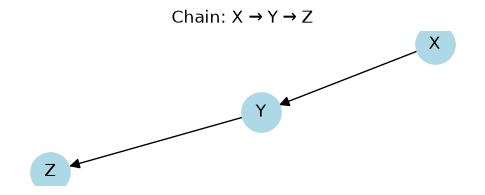

In [5]:
# --- Build the chain X -> Y -> Z ---
chain = nx.DiGraph()
chain.add_edges_from([("X", "Y"), ("Y", "Z")])

draw_graph(chain, title="Chain: X → Y → Z")
plt.show()


### 2. Generate data from the DAG

Each node is a weighted sum of its parents plus noise, so the data
already carries the causal structure the generator will exploit.


In [6]:
rng = np.random.default_rng(42)

X, column_mapping = generate_linear_data(
    chain, n_samples=100, rng=rng,
    coefficients={("X", "Y"): 2.0, ("Y", "Z"): 0.5},
)
print(f"X shape: {X.shape}")
print(f"column_mapping: {column_mapping}")


X shape: (100, 3)
column_mapping: {'X': 0, 'Y': 1, 'Z': 2}


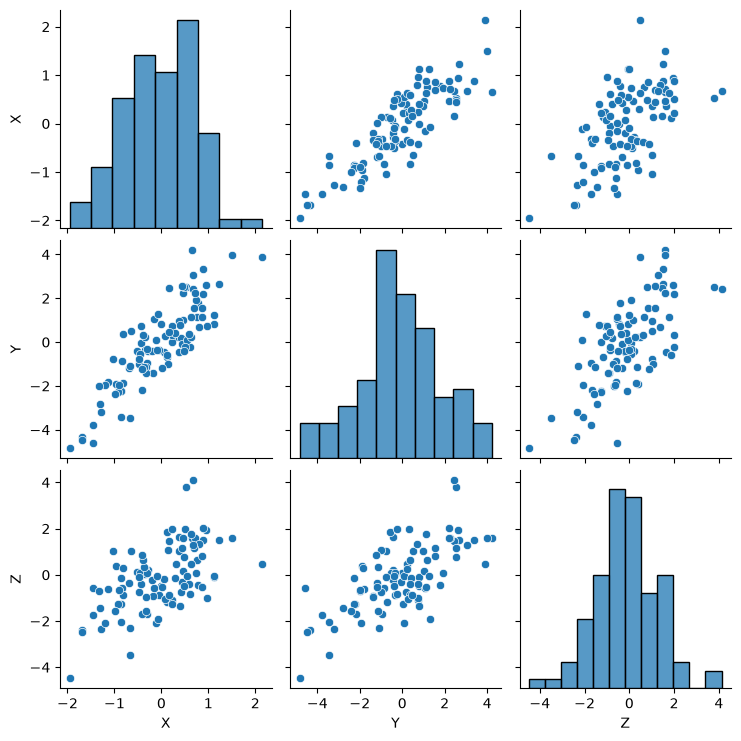

In [7]:
sns.pairplot(pd.DataFrame(X,columns=column_mapping.keys()))

### 3. Fit the DGP

The default backend `OlsDGP` is a deterministic per-node least-squares
backend (pure NumPy): for every non-root node it learns the linear
coefficients from its parents and the residual noise, fitted on the
*original* data.

In [ ]:
dgp = OlsDGP(chain, column_mapping).fit(X.copy())

gen = CausalDriftGenerator(random_generator=np.random.default_rng(0), dgp=dgp)

DGP fitted on 100 rows


### 4. Generate causally-propagated drift

We shift node `Y` and watch it propagate to `Z` (but not to `X`).


In [9]:
Xt, yt = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    drift_std=5.0,
)
print(f"output shape: {Xt.shape}")


output shape: (100, 3)


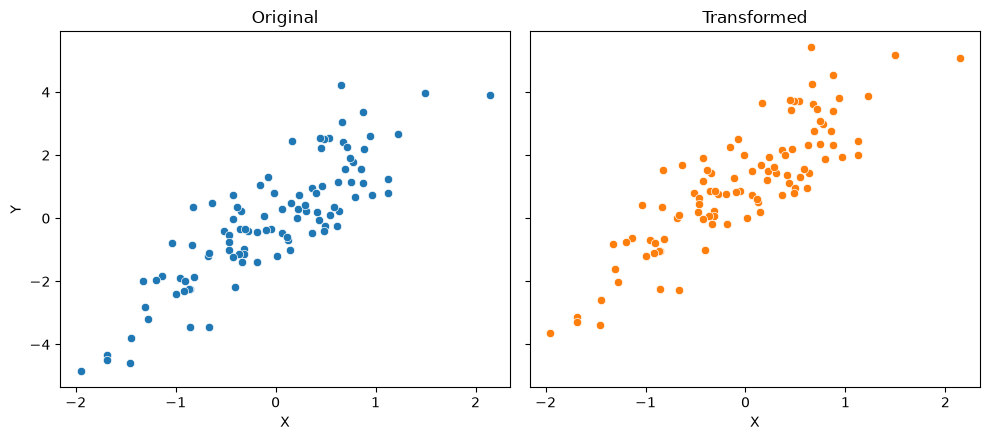

In [10]:
_ = plot_2panel(X, Xt, yt, x_idx=0, y_idx=1, x_name='X', y_name='Y')

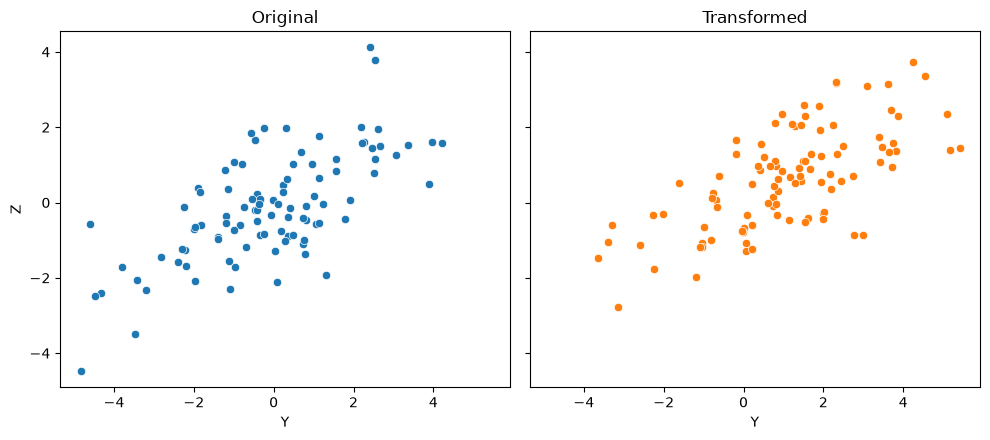

In [11]:
_ = plot_2panel(X, Xt, yt, x_idx=1, y_idx=2, x_name='Y', y_name='Z')

### Propagation to the descendant (Y → Z)

The drift is a single systematic shift, but the propagation is **Pearl surgery with fresh noise**: Z is not translated by a rigid delta — it is **recomputed** from its (shifted) parent through the fitted structural equation, `Z_new = f(Y_shifted) + fresh_noise`. The systematic part of the shift carries through (Z moves because Y moved), but Z's scatter is **re-rolled**, not preserved: the descendant cloud keeps roughly its original width while its position follows the parent's shift. This is what distinguishes drift from noise: drift shifts a node *systematically* (one draw applied to all affected rows), noise scatters it row-by-row — and in both cases the descendants' noise is freshly drawn, never inherited.

## Summary

| Lever | Generator | Uses a DGP? | Propagates? | Selector support ||---|---|---|---|---|
| observation process | `RandomShiftGenerator` | no | no (values only) | — || observation process, per class | `RandomShiftClassesGenerator` | no | no (values only) | `ClassSelector` || DGP | `CausalDriftGenerator` | **yes** (fitted) | **yes** — descendants re-evaluated | yes (boolean masks) |
* Drift is a *single* systematic shift per column, drawn once and
  applied to all affected rows — in contrast to noise, which redraws
  per row.
* `shift_std` / `drift_std` are in units of the column's standard
  deviation (normalize, shift, un-normalize).
* Causal drift mutates `X` in place — pass `X.copy()` if you need the
  original.
